# Анализ данных Airbnb в Нью-Йорке

**Датасет:** New York City Airbnb Open Data  
**Источник:** [Kaggle](https://www.kaggle.com/datasets/dgomonov/new-york-city-airbnb-open-data)  
**Период:** 2019 год  
**Объем:** 48 895 объявлений и 16 исходных признаков


## 1. Введение и постановка цели

### Описание данных

Датасет содержит сведения об объявлениях Airbnb в Нью-Йорке: район, тип жилья, цену, минимальный срок проживания, отзывы, доступность и данные хозяина

Это снимок рынка за 2019 год без фактических бронирований, дохода, площади, количества комнат, удобств и истории цен

### Цель исследования

Определить ключевые факторы цены, выделить пять наиболее важных признаков и построить модель прогнозирования

Качество модели оценивается по MAE, RMSE и R2 на тестовой выборке

### Задачи

- изучить структуру и качество данных
- обработать пропуски, дубликаты и выбросы
- исследовать распределения и связи признаков
- сравнить цены по районам и типам жилья
- проверить гипотезы
- сравнить модели регрессии
- проанализировать ошибки лучшей модели

### Гипотезы

- **H1:** цены различаются между административными районами
- **H2:** `Entire home/apt` дороже, чем `Private room`
- **H3:** цена связана с количеством отзывов
- **H4:** распределение цены после логарифмирования отличается от нормального


In [ ]:
%pip -q install -U "kagglehub[pandas-datasets]"

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

from scipy.stats import (
    normaltest,
    kruskal,
    mannwhitneyu,
    spearmanr
)

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, RobustScaler

from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate,
    GridSearchCV
)

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import kagglehub
from kagglehub import KaggleDatasetAdapter

RANDOM_STATE = 42

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

PASTEL_YELLOW = "#F5D97E"
PASTEL_GREEN = "#A8DDB5"
PASTEL_PINK = "#F4B6C2"
PASTEL_BLUE = "#A9D6E5"
PASTEL_LAVENDER = "#CDB4DB"
PASTEL_COLORS = [
    PASTEL_BLUE,
    PASTEL_GREEN,
    PASTEL_PINK,
    PASTEL_YELLOW,
    PASTEL_LAVENDER
]

BOROUGH_PALETTE = {
    "Bronx": PASTEL_YELLOW,
    "Brooklyn": PASTEL_GREEN,
    "Manhattan": PASTEL_PINK,
    "Queens": PASTEL_BLUE,
    "Staten Island": PASTEL_LAVENDER
}

ROOM_PALETTE = {
    "Entire home/apt": PASTEL_PINK,
    "Private room": PASTEL_BLUE,
    "Shared room": PASTEL_GREEN
}

MODEL_PALETTE = {
    "Линейная регрессия": PASTEL_BLUE,
    "Дерево решений": PASTEL_YELLOW,
    "Случайный лес": PASTEL_GREEN,
    "Градиентный бустинг": PASTEL_PINK
}

PASTEL_DIVERGING_CMAP = LinearSegmentedColormap.from_list(
    "pastel_diverging",
    [PASTEL_BLUE, "#FFFDF8", PASTEL_PINK]
)

sns.set_theme(
    style="whitegrid",
    context="notebook",
    palette=PASTEL_COLORS,
    rc={
        "axes.facecolor": "#FFFDFC",
        "figure.facecolor": "#FFFDFC",
        "grid.color": "#ECE8E1",
        "axes.edgecolor": "#D8D3CB"
    }
)


In [ ]:
dataset_handle = "dgomonov/new-york-city-airbnb-open-data"
file_path = "AB_NYC_2019.csv"

df = kagglehub.dataset_load(
    KaggleDatasetAdapter.PANDAS,
    dataset_handle,
    file_path
)

display(df.head())


Using Colab cache for faster access to the 'new-york-city-airbnb-open-data' dataset.


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.647,-73.972,Private room,149,1,9,2018-10-19,0.210,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.754,-73.984,Entire home/apt,225,1,45,2019-05-21,0.380,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.809,-73.942,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.685,-73.960,Entire home/apt,89,1,270,2019-07-05,4.640,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.799,-73.944,Entire home/apt,80,10,9,2018-11-19,0.100,1,0


## 2. Предварительный обзор данных

Проверяем размер датасета, типы признаков, пропуски, дубликаты, основные статистики и распределение цены


In [ ]:
dataset_size = pd.DataFrame({
    "Строки": [df.shape[0]],
    "Столбцы": [df.shape[1]]
})

display(dataset_size)
df.info()


,Строки,Столбцы
0,48895,16


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

In [ ]:
data_dictionary = {
    "id": "Уникальный идентификатор объявления",
    "name": "Название объявления",
    "host_id": "Уникальный идентификатор хозяина",
    "host_name": "Имя хозяина",
    "neighbourhood_group": "Административный район Нью-Йорка",
    "neighbourhood": "Локальный район",
    "latitude": "Географическая широта",
    "longitude": "Географическая долгота",
    "room_type": "Тип сдаваемого жилья",
    "price": "Заявленная цена за ночь, доллары США",
    "minimum_nights": "Минимальное число ночей",
    "number_of_reviews": "Общее количество отзывов",
    "last_review": "Дата последнего отзыва",
    "reviews_per_month": "Среднее количество отзывов в месяц",
    "calculated_host_listings_count": "Количество объявлений хозяина",
    "availability_365": "Количество доступных дней в году"
}

dictionary_df = pd.DataFrame(
    data_dictionary.items(),
    columns=["Признак", "Описание"]
)

display(dictionary_df)

,Признак,Описание
0,id,Уникальный идентификатор объявления
1,name,Название объявления
2,host_id,Уникальный идентификатор хозяина
3,host_name,Имя хозяина
4,neighbourhood_group,Административный район Нью-Йорка
5,neighbourhood,Локальный район
6,latitude,Географическая широта
7,longitude,Географическая долгота
8,room_type,Тип сдаваемого жилья
9,price,"Заявленная цена за ночь, доллары США"


In [ ]:
missing_report = (
    df.isna()
      .sum()
      .to_frame("Пропусков")
      .assign(Доля=lambda x: x["Пропусков"] / len(df) * 100)
      .sort_values("Пропусков", ascending=False)
)

quality_summary = pd.DataFrame({
    "Показатель": ["Полные дубликаты", "Уникальные ID"],
    "Значение": [df.duplicated().sum(), df["id"].nunique()]
})

display(missing_report[missing_report["Пропусков"] > 0])
display(quality_summary)
display(df.describe().T)


,Пропусков,Доля
last_review,10052,20.558
reviews_per_month,10052,20.558
host_name,21,0.043
name,16,0.033


,Показатель,Значение
0,Полные дубликаты,0
1,Уникальные ID,48895


,count,mean,std,min,25%,50%,75%,max
id,"48,895.000","19,017,143.236","10,983,108.386","2,539.000","9,471,945.000","19,677,284.000","29,152,178.500","36,487,245.000"
host_id,"48,895.000","67,620,010.647","78,610,967.033","2,438.000","7,822,033.000","30,793,816.000","107,434,423.000","274,321,313.000"
latitude,"48,895.000",40.729,0.055,40.500,40.690,40.723,40.763,40.913
longitude,"48,895.000",-73.952,0.046,-74.244,-73.983,-73.956,-73.936,-73.713
price,"48,895.000",152.721,240.154,0.000,69.000,106.000,175.000,"10,000.000"
minimum_nights,"48,895.000",7.030,20.511,1.000,1.000,3.000,5.000,"1,250.000"
number_of_reviews,"48,895.000",23.274,44.551,0.000,1.000,5.000,24.000,629.000
reviews_per_month,"38,843.000",1.373,1.680,0.010,0.190,0.720,2.020,58.500
calculated_host_listings_count,"48,895.000",7.144,32.953,1.000,1.000,1.000,2.000,327.000
availability_365,"48,895.000",112.781,131.622,0.000,0.000,45.000,227.000,365.000


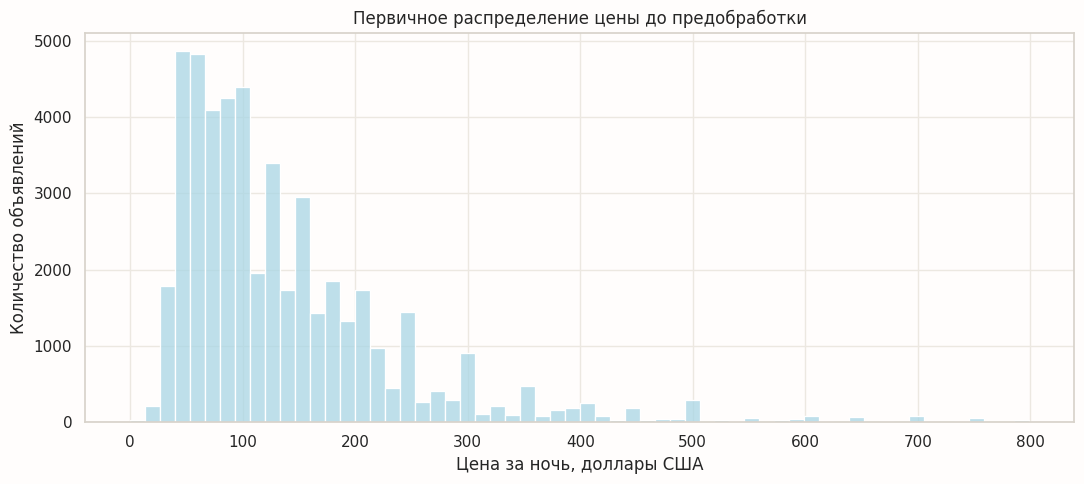

,Показатель,Цена
0,Медиана,106.000
1,Среднее,152.721
2,Максимум,"10,000.000"


In [ ]:
raw_price_limit = df["price"].quantile(0.99)

plt.figure(figsize=(11, 5))
sns.histplot(
    data=df[df["price"] <= raw_price_limit],
    x="price",
    bins=60,
    color=PASTEL_BLUE
)

plt.title("Первичное распределение цены до предобработки")
plt.xlabel("Цена за ночь, доллары США")
plt.ylabel("Количество объявлений")
plt.tight_layout()
plt.show()

price_summary = pd.DataFrame({
    "Показатель": ["Медиана", "Среднее", "Максимум"],
    "Цена": [df["price"].median(), df["price"].mean(), df["price"].max()]
})

display(price_summary)


## 3. Предобработка данных

- преобразуем дату последнего отзыва
- заменяем пропуски в названиях и именах хозяев
- заполняем пропуски в `reviews_per_month` нулями
- удаляем полные дубликаты и некорректные цены
- исключаем объявления выше 99-го процентиля цены
- создаем признаки активности объявления и хозяина

Потенциальные повторы по бизнес-признакам не удаляем, так как разные объявления могут иметь одинаковые характеристики


In [ ]:
df_raw = df.copy()
df_clean = df.copy()

rows_initial = len(df_clean)

df_clean["last_review"] = pd.to_datetime(
    df_clean["last_review"],
    errors="coerce"
)

df_clean["name"] = df_clean["name"].fillna("Не указано")
df_clean["host_name"] = df_clean["host_name"].fillna("Не указано")
df_clean["reviews_per_month"] = df_clean["reviews_per_month"].fillna(0)

duplicates_before = df_clean.duplicated().sum()
df_clean = df_clean.drop_duplicates()

required_columns = [
    "neighbourhood_group",
    "neighbourhood",
    "room_type",
    "price",
    "latitude",
    "longitude"
]

rows_before_required = len(df_clean)
df_clean = df_clean.dropna(subset=required_columns)
dropped_required = rows_before_required - len(df_clean)

rows_before_invalid_price = len(df_clean)
df_clean = df_clean[df_clean["price"] > 0].copy()
dropped_invalid_price = rows_before_invalid_price - len(df_clean)

price_upper = df_clean["price"].quantile(0.99)

rows_before_price_outliers = len(df_clean)
df_clean = df_clean[df_clean["price"] <= price_upper].copy()
dropped_price_outliers = rows_before_price_outliers - len(df_clean)

df_clean = df_clean.reset_index(drop=True)

cleaning_summary = pd.DataFrame({
    "Показатель": [
        "Исходные строки",
        "Полные дубликаты",
        "Строки без обязательных значений",
        "Некорректные цены",
        "Ценовые выбросы",
        "Итоговые строки"
    ],
    "Значение": [
        rows_initial,
        duplicates_before,
        dropped_required,
        dropped_invalid_price,
        dropped_price_outliers,
        len(df_clean)
    ]
})

display(cleaning_summary)


,Показатель,Значение
0,Исходные строки,48895
1,Полные дубликаты,0
2,Строки без обязательных значений,0
3,Некорректные цены,11
4,Ценовые выбросы,474
5,Итоговые строки,48410


In [ ]:
df_clean["has_reviews"] = (
    df_clean["number_of_reviews"] > 0
).astype(int)

reference_date = df_clean["last_review"].max()

df_clean["days_since_last_review"] = (
    reference_date - df_clean["last_review"]
).dt.days

df_clean.loc[
    df_clean["has_reviews"] == 0,
    "days_since_last_review"
] = np.nan

df_clean["name_length"] = df_clean["name"].astype(str).str.len()

df_clean["is_multi_listing_host"] = (
    df_clean["calculated_host_listings_count"] > 1
).astype(int)

df_clean["price_log"] = np.log1p(df_clean["price"])

display(df_clean.head())


,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365,has_reviews,days_since_last_review,name_length,is_multi_listing_host,price_log
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.647,-73.972,Private room,149,1,9,2018-10-19,0.210,6,365,1,262.000,34,1,5.011
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.754,-73.984,Entire home/apt,225,1,45,2019-05-21,0.380,2,355,1,48.000,21,1,5.421
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.809,-73.942,Private room,150,3,0,NaT,0.000,1,365,0,NaN,35,0,5.017
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.685,-73.960,Entire home/apt,89,1,270,2019-07-05,4.640,1,194,1,3.000,31,0,4.500
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.799,-73.944,Entire home/apt,80,10,9,2018-11-19,0.100,1,0,1,231.000,48,0,4.394


In [ ]:
business_key = [
    "host_id",
    "neighbourhood",
    "latitude",
    "longitude",
    "room_type",
    "price"
]

suspected_business_duplicates = (
    df_clean.duplicated(
        subset=business_key,
        keep=False
    ).sum()
)

cleaning_report = pd.DataFrame({
    "Показатель": [
        "Строк до обработки",
        "Строк после обработки",
        "Удалено полных дубликатов",
        "Удалено некорректных цен",
        "Удалено верхних ценовых выбросов",
        "Потенциальные повторы",
        "Пропуски в reviews_per_month",
        "Пропуски в last_review"
    ],
    "Значение": [
        rows_initial,
        len(df_clean),
        duplicates_before,
        dropped_invalid_price,
        dropped_price_outliers,
        suspected_business_duplicates,
        df_clean["reviews_per_month"].isna().sum(),
        df_clean["last_review"].isna().sum()
    ]
})

display(cleaning_report)


,Показатель,Значение
0,Строк до обработки,48895
1,Строк после обработки,48410
2,Удалено полных дубликатов,0
3,Удалено некорректных цен,11
4,Удалено верхних ценовых выбросов,474
5,Потенциальные повторы,2
6,Пропуски в reviews_per_month,0
7,Пропуски в last_review,9827


## 4. Исследовательский анализ данных

Изучаем распределение цены, различия между районами и типами жилья, корреляции и статистическую значимость гипотез

Используем уровень значимости `α = 0.05`, критерии Краскела-Уоллиса и Манна-Уитни, а также корреляцию Спирмена

Статистическую значимость оцениваем вместе с размером эффекта


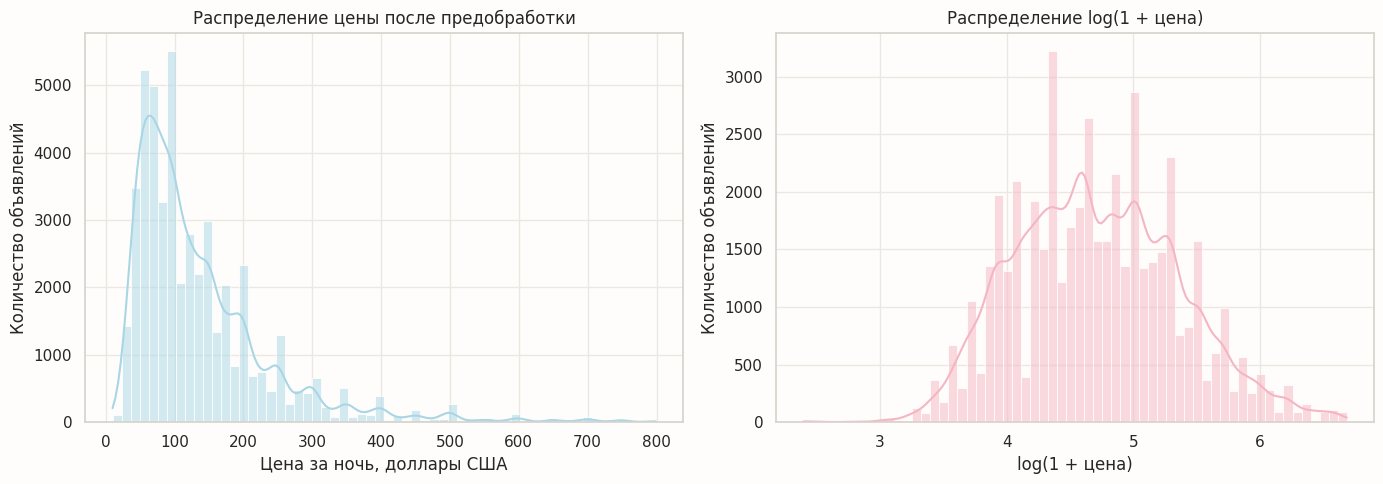

,Показатель,Значение
0,Средняя цена,137.575
1,Медианная цена,105.000
2,Асимметрия цены,2.271
3,Асимметрия log-цены,0.235
4,p-value теста нормальности,0.000


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df_clean,
    x="price",
    bins=60,
    kde=True,
    color=PASTEL_BLUE,
    ax=axes[0]
)
axes[0].set_title("Распределение цены после предобработки")
axes[0].set_xlabel("Цена за ночь, доллары США")
axes[0].set_ylabel("Количество объявлений")

sns.histplot(
    data=df_clean,
    x="price_log",
    bins=60,
    kde=True,
    color=PASTEL_PINK,
    ax=axes[1]
)
axes[1].set_title("Распределение log(1 + цена)")
axes[1].set_xlabel("log(1 + цена)")
axes[1].set_ylabel("Количество объявлений")

plt.tight_layout()
plt.show()

normal_stat, normal_p = normaltest(df_clean["price_log"])

distribution_summary = pd.DataFrame({
    "Показатель": [
        "Средняя цена",
        "Медианная цена",
        "Асимметрия цены",
        "Асимметрия log-цены",
        "p-value теста нормальности"
    ],
    "Значение": [
        df_clean["price"].mean(),
        df_clean["price"].median(),
        df_clean["price"].skew(),
        df_clean["price_log"].skew(),
        normal_p
    ]
})

display(distribution_summary)


In [ ]:
neighbourhood_summary = (
    df_clean
    .groupby("neighbourhood_group")
    .agg(
        listings=("id", "count"),
        mean_price=("price", "mean"),
        median_price=("price", "median"),
        price_std=("price", "std")
    )
    .sort_values("median_price", ascending=False)
)

room_summary = (
    df_clean
    .groupby("room_type")
    .agg(
        listings=("id", "count"),
        mean_price=("price", "mean"),
        median_price=("price", "median"),
        price_std=("price", "std")
    )
    .sort_values("median_price", ascending=False)
)

display(neighbourhood_summary)
display(room_summary)


,listings,mean_price,median_price,price_std
neighbourhood_group,,,,
Manhattan,21312,172.902,149.000,116.470
Brooklyn,19992,115.922,90.000,85.877
Queens,5650,94.105,75.000,69.191
Staten Island,369,94.241,75.000,75.690
Bronx,1087,83.863,65.000,69.391


,listings,mean_price,median_price,price_std
room_type,,,,
Entire home/apt,25022,189.100,160.000,109.659
Private room,22237,83.395,70.000,59.366
Shared room,1151,64.203,45.000,60.657


In [ ]:
ALPHA = 0.05

neighbourhood_groups = [
    group["price"].values
    for _, group in df_clean.groupby("neighbourhood_group")
]

kw_stat, kw_p = kruskal(*neighbourhood_groups)

n_total = len(df_clean)
k_groups = df_clean["neighbourhood_group"].nunique()

kw_effect = max(
    0,
    (kw_stat - k_groups + 1) / (n_total - k_groups)
)

entire_prices = df_clean.loc[
    df_clean["room_type"] == "Entire home/apt",
    "price"
]

private_prices = df_clean.loc[
    df_clean["room_type"] == "Private room",
    "price"
]

u_stat, mw_p = mannwhitneyu(
    entire_prices,
    private_prices,
    alternative="greater"
)

rank_biserial = (
    2 * u_stat / (len(entire_prices) * len(private_prices)) - 1
)

spearman_r, spearman_p = spearmanr(
    df_clean["price"],
    df_clean["number_of_reviews"]
)

def format_p_value(value):
    return f"{value:.2e}" if value < 0.001 else f"{value:.3f}"

if kw_p < ALPHA:
    h1_result = "Цены различаются, размер эффекта заметный"
else:
    h1_result = "Значимых различий не обнаружено"

if mw_p < ALPHA and rank_biserial > 0:
    h2_result = "Entire home/apt дороже, эффект сильный"
else:
    h2_result = "Гипотеза не получила подтверждения"

if spearman_p < ALPHA and abs(spearman_r) < 0.1:
    h3_result = "Связь значима, но практически отсутствует"
elif spearman_p < ALPHA:
    h3_result = "Обнаружена статистически значимая связь"
else:
    h3_result = "Статистически значимая связь не обнаружена"

if normal_p < ALPHA:
    h4_result = "Нормальность log-цены отвергается"
else:
    h4_result = "Нет оснований отвергать нормальность log-цены"

hypothesis_results = pd.DataFrame({
    "Гипотеза": [
        "H1: цены различаются между районами",
        "H2: Entire home/apt дороже Private room",
        "H3: цена связана с количеством отзывов",
        "H4: log-цена отличается от нормального распределения"
    ],
    "Статистика": [
        kw_stat,
        u_stat,
        spearman_r,
        normal_stat
    ],
    "p-value": [
        format_p_value(kw_p),
        format_p_value(mw_p),
        format_p_value(spearman_p),
        format_p_value(normal_p)
    ],
    "Размер эффекта или связь": [
        kw_effect,
        rank_biserial,
        spearman_r,
        np.nan
    ],
    "Решение": [
        h1_result,
        h2_result,
        h3_result,
        h4_result
    ]
})

display(hypothesis_results)


,Гипотеза,Статистика,p-value,Размер эффекта или связь,Решение
0,H1: цены различаются между районами,"6,868.129",0.00e+00,0.142,"Цены различаются, размер эффекта заметный"
1,H2: Entire home/apt дороже Private room,"494,965,110.500",0.00e+00,0.779,"Entire home/apt дороже, эффект сильный"
2,H3: цена связана с количеством отзывов,-0.046,2.36e-24,-0.046,"Связь значима, но практически отсутствует"
3,H4: log-цена отличается от нормального распред...,594.725,7.20e-130,NaN,Нормальность log-цены отвергается


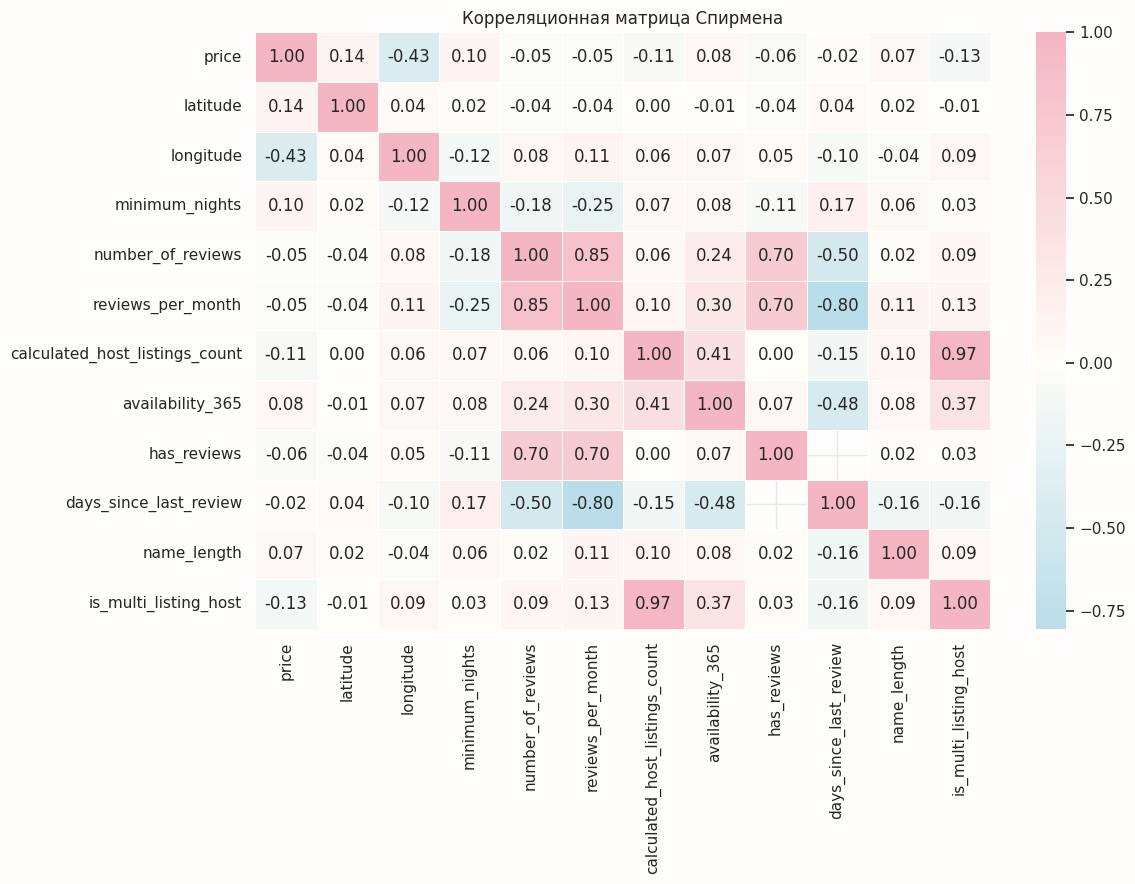

,Корреляция с ценой
longitude,-0.435
latitude,0.136
is_multi_listing_host,-0.129
calculated_host_listings_count,-0.107
minimum_nights,0.105
availability_365,0.080
name_length,0.073
has_reviews,-0.059
reviews_per_month,-0.051
number_of_reviews,-0.046


In [ ]:
numeric_for_correlation = [
    "price",
    "latitude",
    "longitude",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365",
    "has_reviews",
    "days_since_last_review",
    "name_length",
    "is_multi_listing_host"
]

correlation_matrix = (
    df_clean[numeric_for_correlation]
    .corr(method="spearman")
)

plt.figure(figsize=(12, 9))
sns.heatmap(
    correlation_matrix,
    cmap=PASTEL_DIVERGING_CMAP,
    center=0,
    annot=True,
    fmt=".2f",
    linewidths=0.7,
    linecolor="#FFFFFF"
)

plt.title("Корреляционная матрица Спирмена")
plt.tight_layout()
plt.show()

price_correlations = (
    correlation_matrix["price"]
    .drop("price")
    .sort_values(key=np.abs, ascending=False)
    .to_frame("Корреляция с ценой")
)

display(price_correlations)


## 5. Визуализация данных

Строим столбчатые диаграммы, боксплоты, violin plot, диаграммы рассеяния, географическую карту и корреляционную матрицу

Цена на графиках указана в долларах США за ночь


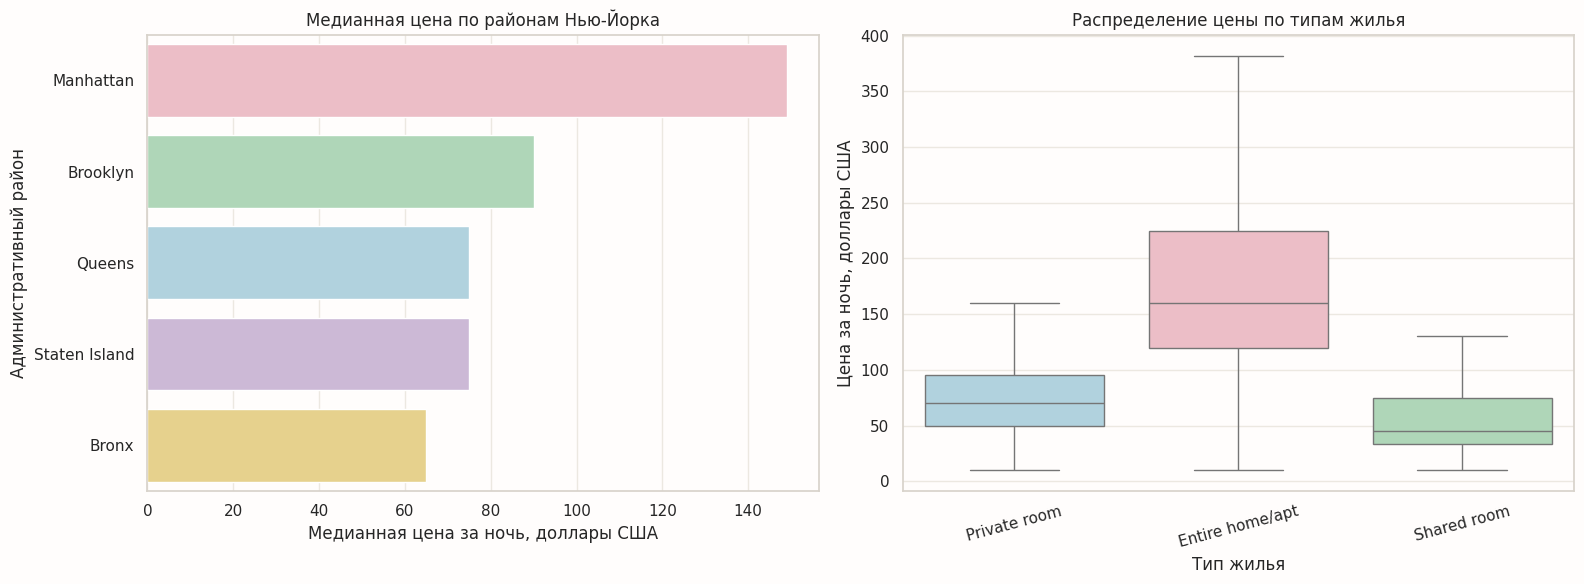

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

neighbourhood_plot = neighbourhood_summary.reset_index()

sns.barplot(
    data=neighbourhood_plot,
    x="median_price",
    y="neighbourhood_group",
    hue="neighbourhood_group",
    palette=BOROUGH_PALETTE,
    legend=False,
    ax=axes[0]
)

axes[0].set_title("Медианная цена по районам Нью-Йорка")
axes[0].set_xlabel("Медианная цена за ночь, доллары США")
axes[0].set_ylabel("Административный район")

sns.boxplot(
    data=df_clean,
    x="room_type",
    y="price",
    hue="room_type",
    palette=ROOM_PALETTE,
    showfliers=False,
    legend=False,
    linewidth=1,
    ax=axes[1]
)

axes[1].set_title("Распределение цены по типам жилья")
axes[1].set_xlabel("Тип жилья")
axes[1].set_ylabel("Цена за ночь, доллары США")
axes[1].tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.show()


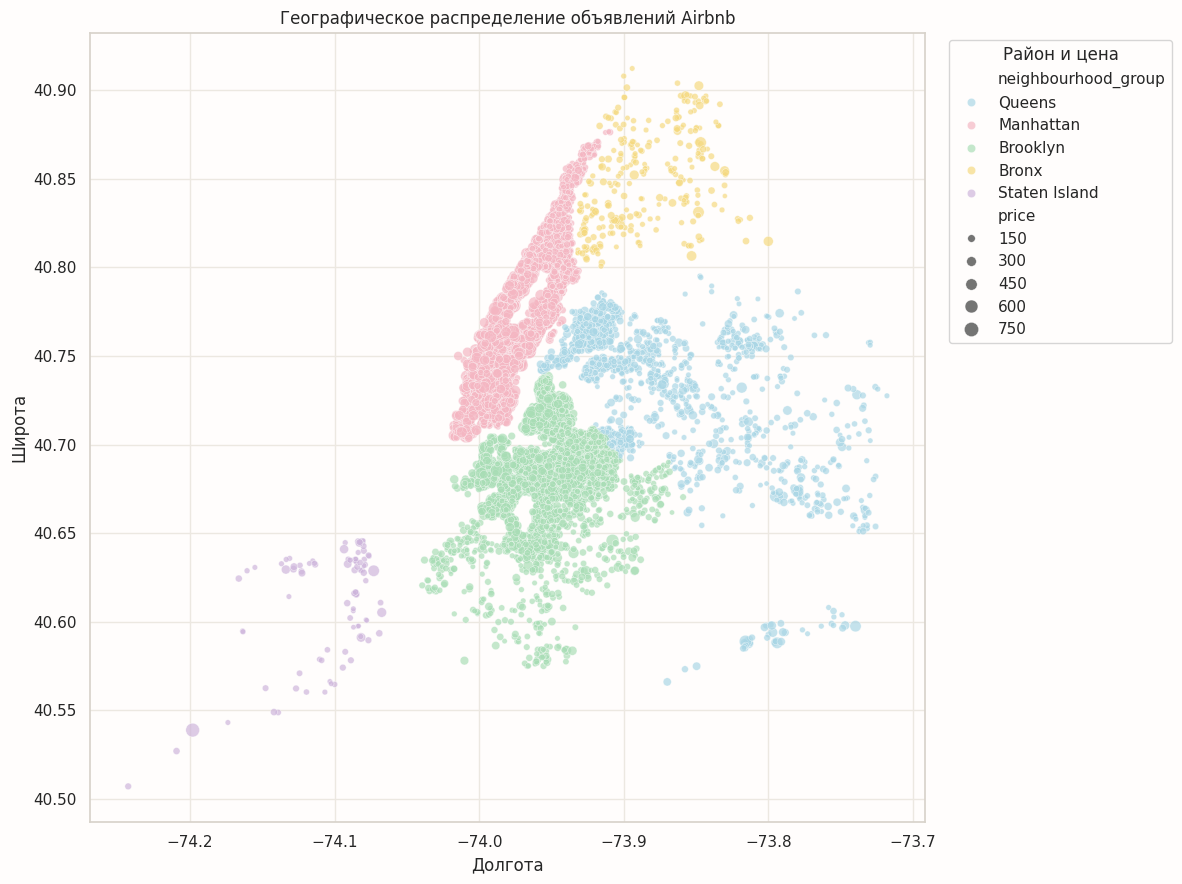

In [ ]:
map_sample = df_clean.sample(
    n=min(12_000, len(df_clean)),
    random_state=RANDOM_STATE
)

plt.figure(figsize=(12, 9))

sns.scatterplot(
    data=map_sample,
    x="longitude",
    y="latitude",
    hue="neighbourhood_group",
    size="price",
    palette=BOROUGH_PALETTE,
    sizes=(12, 110),
    alpha=0.68,
    linewidth=0.35,
    edgecolor="#FFFFFF"
)

plt.title("Географическое распределение объявлений Airbnb")
plt.xlabel("Долгота")
plt.ylabel("Широта")
plt.legend(
    title="Район и цена",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()


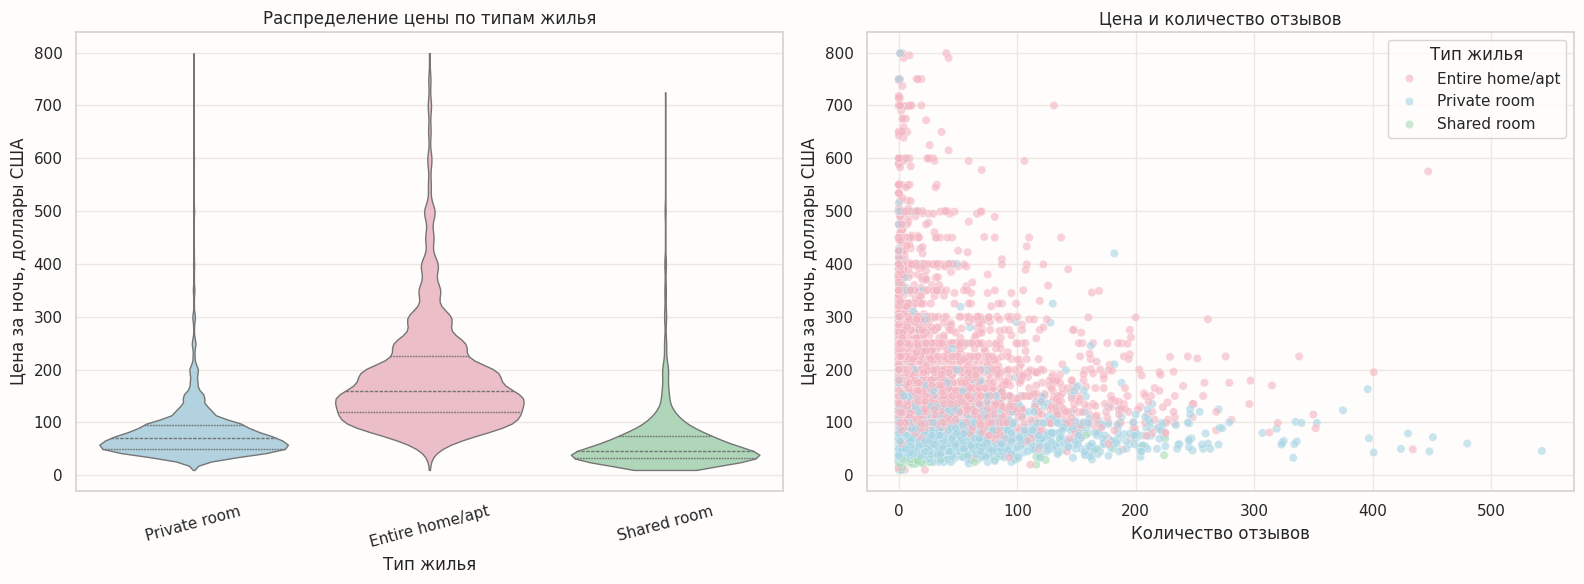

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.violinplot(
    data=df_clean,
    x="room_type",
    y="price",
    hue="room_type",
    palette=ROOM_PALETTE,
    inner="quartile",
    cut=0,
    legend=False,
    linewidth=1,
    ax=axes[0]
)

axes[0].set_title("Распределение цены по типам жилья")
axes[0].set_xlabel("Тип жилья")
axes[0].set_ylabel("Цена за ночь, доллары США")
axes[0].tick_params(axis="x", rotation=15)

scatter_sample = df_clean.sample(
    n=min(10_000, len(df_clean)),
    random_state=RANDOM_STATE
)

sns.scatterplot(
    data=scatter_sample,
    x="number_of_reviews",
    y="price",
    hue="room_type",
    palette=ROOM_PALETTE,
    alpha=0.62,
    linewidth=0.3,
    edgecolor="#FFFFFF",
    ax=axes[1]
)

axes[1].set_title("Цена и количество отзывов")
axes[1].set_xlabel("Количество отзывов")
axes[1].set_ylabel("Цена за ночь, доллары США")
axes[1].legend(title="Тип жилья")

plt.tight_layout()
plt.show()


## 6. Прогнозирование и моделирование

### Целевая переменная

Целевая переменная `price` показывает заявленную цену за ночь

### Исключенные признаки

- `id` и `host_id` как идентификаторы
- `host_name` как имя хозяина
- `name` без отдельной обработки текста
- `last_review`, вместо него используется давность отзыва
- `price_log` как преобразование целевой переменной

### Подготовка

- числовые пропуски заполняются медианой
- категории кодируются методом One-Hot Encoding
- числовые признаки масштабируются через RobustScaler
- цена преобразуется функцией `log(1 + price)`
- данные делятся на обучающую и тестовую выборки 80/20
- модели сравниваются по трехкратной кросс-валидации


In [ ]:
feature_columns = [
    "neighbourhood_group",
    "neighbourhood",
    "room_type",
    "latitude",
    "longitude",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365",
    "has_reviews",
    "days_since_last_review",
    "name_length",
    "is_multi_listing_host"
]

target_column = "price"

X = df_clean[feature_columns].copy()
y = df_clean[target_column].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

split_summary = pd.DataFrame({
    "Выборка": ["Обучающая", "Тестовая"],
    "Строки": [X_train.shape[0], X_test.shape[0]],
    "Признаки": [X_train.shape[1], X_test.shape[1]]
})

display(split_summary)


,Выборка,Строки,Признаки
0,Обучающая,38728,14
1,Тестовая,9682,14


In [ ]:
categorical_features = [
    "neighbourhood_group",
    "neighbourhood",
    "room_type"
]

numeric_features = [
    column
    for column in feature_columns
    if column not in categorical_features
]

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    (
        "onehot",
        OneHotEncoder(
            handle_unknown="ignore",
            min_frequency=10,
            sparse_output=False
        )
    )
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

def make_model(regressor):
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", regressor)
    ])

    return TransformedTargetRegressor(
        regressor=pipeline,
        func=np.log1p,
        inverse_func=np.expm1,
        check_inverse=False
    )

models = {
    "Линейная регрессия": make_model(LinearRegression()),
    "Дерево решений": make_model(
        DecisionTreeRegressor(
            max_depth=15,
            min_samples_leaf=5,
            random_state=RANDOM_STATE
        )
    ),
    "Случайный лес": make_model(
        RandomForestRegressor(
            n_estimators=150,
            max_depth=20,
            min_samples_leaf=2,
            random_state=RANDOM_STATE,
            n_jobs=1
        )
    ),
    "Градиентный бустинг": make_model(
        GradientBoostingRegressor(
            n_estimators=150,
            learning_rate=0.05,
            max_depth=3,
            random_state=RANDOM_STATE
        )
    )
}


,Модель,CV_MAE,CV_MAE_std,CV_RMSE,CV_R2
0,Случайный лес,42.285,0.185,74.409,0.485
1,Градиентный бустинг,43.997,0.380,78.365,0.428
2,Линейная регрессия,45.999,0.371,80.732,0.393
3,Дерево решений,49.222,0.286,82.572,0.365


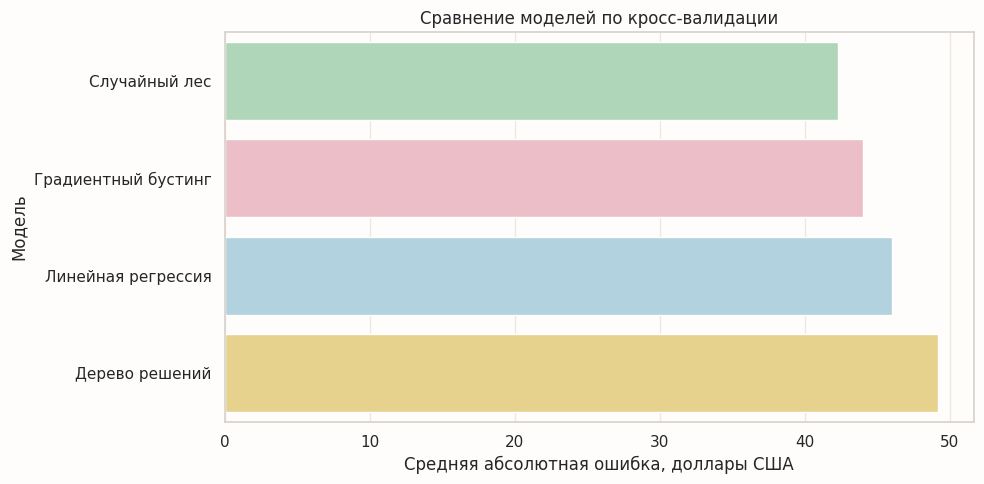

,Модель,CV_MAE,CV_MAE_std,CV_RMSE,CV_R2
0,Случайный лес,42.285,0.185,74.409,0.485
1,Градиентный бустинг,43.997,0.380,78.365,0.428
2,Линейная регрессия,45.999,0.371,80.732,0.393
3,Дерево решений,49.222,0.286,82.572,0.365


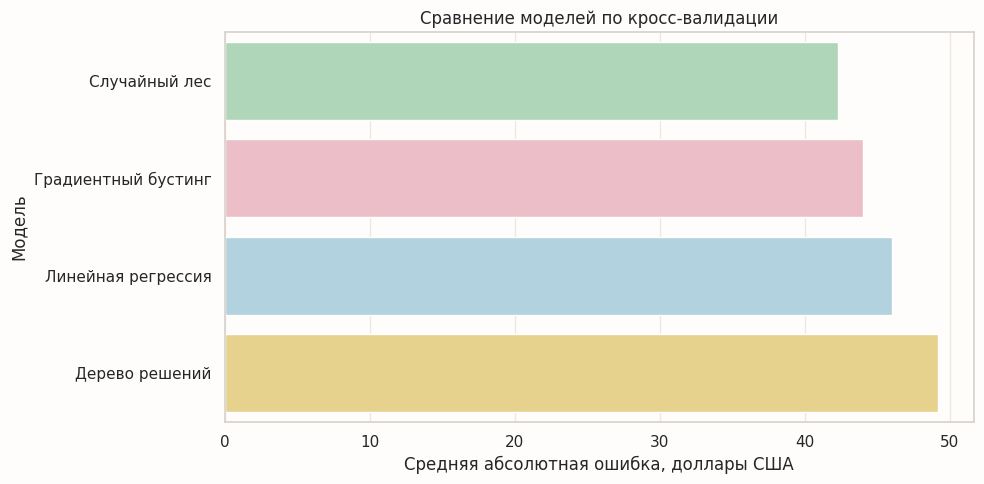

In [ ]:
cv = KFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

scoring = {
    "MAE": "neg_mean_absolute_error",
    "RMSE": "neg_root_mean_squared_error",
    "R2": "r2"
}

cv_rows = []

for model_name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
        return_train_score=False
    )

    cv_rows.append({
        "Модель": model_name,
        "CV_MAE": -scores["test_MAE"].mean(),
        "CV_MAE_std": scores["test_MAE"].std(),
        "CV_RMSE": -scores["test_RMSE"].mean(),
        "CV_R2": scores["test_R2"].mean()
    })

cv_results = (
    pd.DataFrame(cv_rows)
    .sort_values("CV_MAE")
    .reset_index(drop=True)
)

display(cv_results)

plt.figure(figsize=(10, 5))
sns.barplot(
    data=cv_results,
    x="CV_MAE",
    y="Модель",
    hue="Модель",
    palette=MODEL_PALETTE,
    legend=False,
)

plt.title("Сравнение моделей по кросс-валидации")
plt.xlabel("Средняя абсолютная ошибка, доллары США")
plt.ylabel("Модель")
plt.tight_layout()
plt.show()


In [ ]:
ensemble_names = [
    "Случайный лес",
    "Градиентный бустинг"
]

best_ensemble_name = (
    cv_results[
        cv_results["Модель"].isin(ensemble_names)
    ]
    .sort_values("CV_MAE")
    .iloc[0]["Модель"]
)

if best_ensemble_name == "Случайный лес":
    parameter_grid = {
        "regressor__model__n_estimators": [150, 250],
        "regressor__model__max_depth": [15, 25],
        "regressor__model__min_samples_leaf": [1, 3]
    }
else:
    parameter_grid = {
        "regressor__model__n_estimators": [100, 200],
        "regressor__model__learning_rate": [0.05, 0.10],
        "regressor__model__max_depth": [2, 3]
    }

grid_search = GridSearchCV(
    estimator=models[best_ensemble_name],
    param_grid=parameter_grid,
    scoring="neg_mean_absolute_error",
    cv=cv,
    n_jobs=-1,
    verbose=0,
    refit=True
)

grid_search.fit(X_train, y_train)

tuned_cv_mae = -grid_search.best_score_

tuning_result = pd.DataFrame({
    "Модель": [best_ensemble_name],
    "CV_MAE": [tuned_cv_mae],
    "Параметры": [grid_search.best_params_]
})

display(tuning_result)


,Модель,CV_MAE,Параметры
0,Случайный лес,42.255,"{'regressor__model__max_depth': 15, 'regressor..."


In [ ]:
overall_best_name = cv_results.iloc[0]["Модель"]
overall_best_cv_mae = cv_results.iloc[0]["CV_MAE"]

if tuned_cv_mae <= overall_best_cv_mae:
    final_model = grid_search.best_estimator_
    final_model_name = f"{best_ensemble_name} после настройки"
    final_cv_mae = tuned_cv_mae
else:
    final_model = models[overall_best_name]
    final_model_name = overall_best_name
    final_cv_mae = overall_best_cv_mae

final_model.fit(X_train, y_train)

y_pred = np.maximum(final_model.predict(X_test), 0)

test_mae = mean_absolute_error(y_test, y_pred)
test_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
test_r2 = r2_score(y_test, y_pred)

test_metrics = pd.DataFrame({
    "Модель": [final_model_name] * 4,
    "Метрика": ["CV_MAE", "Test_MAE", "Test_RMSE", "Test_R2"],
    "Значение": [final_cv_mae, test_mae, test_rmse, test_r2]
})

display(test_metrics)


,Модель,Метрика,Значение
0,Случайный лес после настройки,CV_MAE,42.255
1,Случайный лес после настройки,Test_MAE,41.881
2,Случайный лес после настройки,Test_RMSE,73.093
3,Случайный лес после настройки,Test_R2,0.509


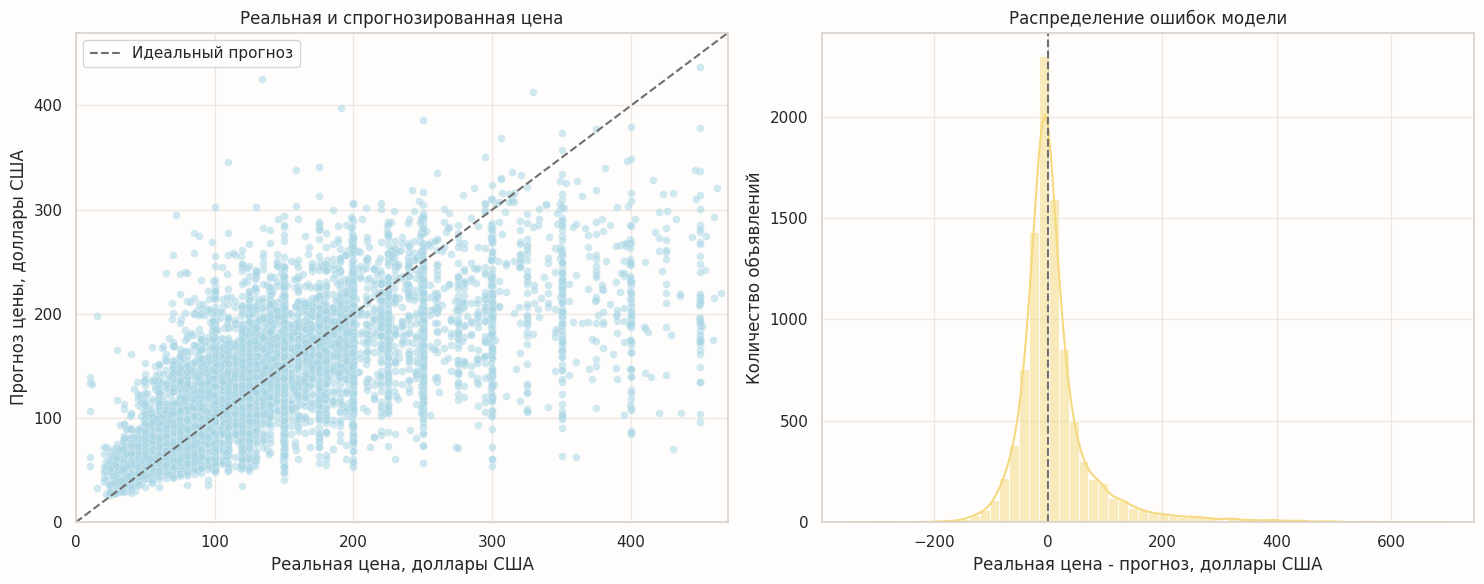

In [ ]:
prediction_limit = np.quantile(
    np.concatenate([y_test.values, y_pred]),
    0.99
)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.scatterplot(
    x=y_test,
    y=y_pred,
    alpha=0.55,
    color=PASTEL_BLUE,
    edgecolor="#FFFFFF",
    linewidth=0.25,
    s=32,
    ax=axes[0]
)

axes[0].plot(
    [0, prediction_limit],
    [0, prediction_limit],
    linestyle="--",
    color="#6F6F6F",
    label="Идеальный прогноз"
)

axes[0].set_xlim(0, prediction_limit)
axes[0].set_ylim(0, prediction_limit)
axes[0].set_title("Реальная и спрогнозированная цена")
axes[0].set_xlabel("Реальная цена, доллары США")
axes[0].set_ylabel("Прогноз цены, доллары США")
axes[0].legend()

residuals = y_test.values - y_pred

sns.histplot(
    residuals,
    bins=60,
    kde=True,
    color=PASTEL_YELLOW,
    ax=axes[1]
)

axes[1].axvline(0, color="#6F6F6F", linestyle="--")
axes[1].set_title("Распределение ошибок модели")
axes[1].set_xlabel("Реальная цена - прогноз, доллары США")
axes[1].set_ylabel("Количество объявлений")

plt.tight_layout()
plt.show()


In [ ]:
error_df = df_clean.loc[
    X_test.index,
    [
        "id",
        "neighbourhood_group",
        "neighbourhood",
        "room_type",
        "price"
    ]
].copy()

error_df["predicted_price"] = y_pred
error_df["residual"] = error_df["price"] - error_df["predicted_price"]
error_df["absolute_error"] = error_df["residual"].abs()

room_error = (
    error_df
    .groupby("room_type")
    .agg(
        listings=("id", "count"),
        MAE=("absolute_error", "mean"),
        median_error=("absolute_error", "median"),
        mean_residual=("residual", "mean")
    )
    .reset_index()
    .rename(columns={"room_type": "Группа"})
    .assign(Срез="Тип жилья")
)

neighbourhood_error = (
    error_df
    .groupby("neighbourhood_group")
    .agg(
        listings=("id", "count"),
        MAE=("absolute_error", "mean"),
        median_error=("absolute_error", "median"),
        mean_residual=("residual", "mean")
    )
    .reset_index()
    .rename(columns={"neighbourhood_group": "Группа"})
    .assign(Срез="Район")
)

group_error = (
    pd.concat([room_error, neighbourhood_error], ignore_index=True)
    .sort_values(["Срез", "MAE"], ascending=[True, False])
)

display(group_error)
display(error_df.sort_values("absolute_error", ascending=False).head(10))


,Группа,listings,MAE,median_error,mean_residual,Срез
5,Manhattan,4201,52.377,29.925,14.493,Район
7,Staten Island,75,42.488,20.118,14.712,Район
4,Brooklyn,4074,35.390,19.816,10.065,Район
6,Queens,1110,28.785,16.662,6.837,Район
3,Bronx,222,27.637,16.275,1.354,Район
0,Entire home/apt,5049,58.427,37.205,16.518,Тип жилья
2,Shared room,250,26.524,11.034,10.540,Тип жилья
1,Private room,4383,23.696,14.319,5.669,Тип жилья


,id,neighbourhood_group,neighbourhood,room_type,price,predicted_price,residual,absolute_error
7901,6165564,Brooklyn,Bedford-Stuyvesant,Private room,750,56.961,693.039,693.039
43170,33741545,Queens,Astoria,Private room,700,80.137,619.863,619.863
3022,1798271,Staten Island,Woodrow,Entire home/apt,700,109.034,590.966,590.966
24670,19964849,Manhattan,Upper East Side,Entire home/apt,795,211.554,583.446,583.446
26194,21054217,Manhattan,Chelsea,Entire home/apt,790,219.570,570.430,570.430
38471,30399838,Manhattan,Upper West Side,Entire home/apt,750,195.750,554.250,554.250
3444,2082694,Brooklyn,Williamsburg,Entire home/apt,700,152.148,547.852,547.852
47342,35936418,Manhattan,Financial District,Entire home/apt,699,156.208,542.792,542.792
47861,36207223,Manhattan,Chelsea,Entire home/apt,750,233.073,516.927,516.927
17406,13824020,Brooklyn,Park Slope,Entire home/apt,700,195.166,504.834,504.834


,Признак,Важность
0,room_type_Entire home/apt,0.506
1,longitude,0.104
2,latitude,0.100
3,availability_365,0.053
4,neighbourhood_group_Manhattan,0.044
5,minimum_nights,0.033
6,name_length,0.032
7,reviews_per_month,0.026
8,number_of_reviews,0.023
9,days_since_last_review,0.022


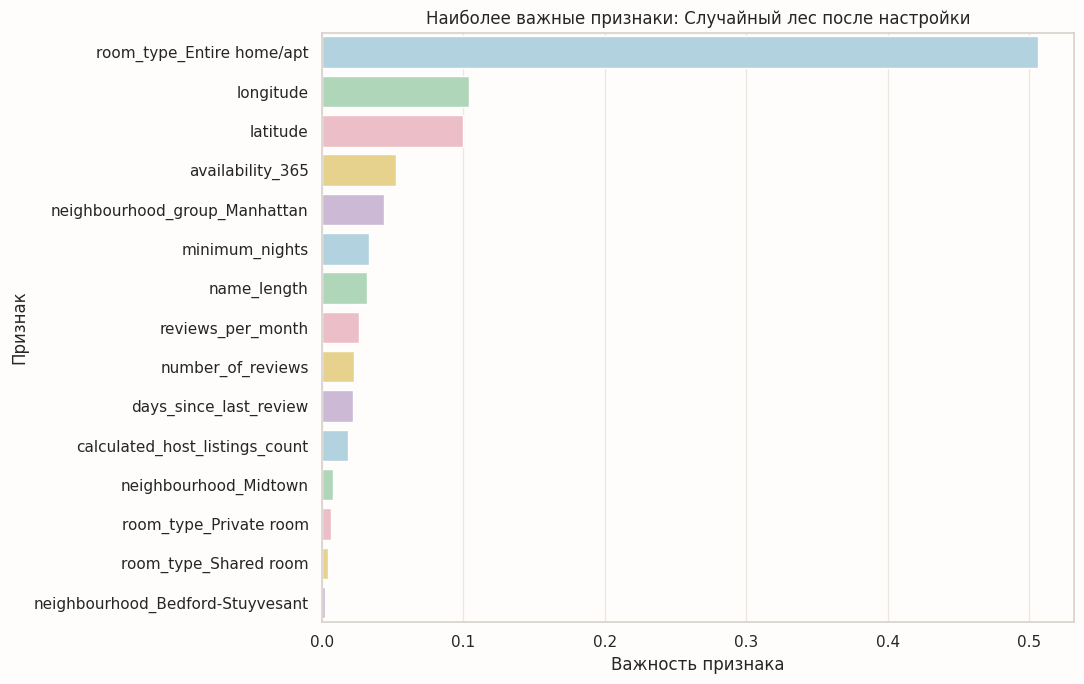

In [ ]:
fitted_pipeline = final_model.regressor_

feature_names = (
    fitted_pipeline
    .named_steps["preprocessor"]
    .get_feature_names_out()
)

fitted_estimator = fitted_pipeline.named_steps["model"]

if hasattr(fitted_estimator, "feature_importances_"):
    importance_values = fitted_estimator.feature_importances_
    importance_type = "Важность признака"
elif hasattr(fitted_estimator, "coef_"):
    importance_values = np.abs(np.ravel(fitted_estimator.coef_))
    importance_type = "Модуль коэффициента"
else:
    raise ValueError("Для выбранной модели не удалось получить важность признаков")

importance_df = pd.DataFrame({
    "Признак": feature_names,
    "Важность": importance_values
})

importance_df["Признак"] = (
    importance_df["Признак"]
    .str.replace("num__", "", regex=False)
    .str.replace("cat__", "", regex=False)
)

importance_df = (
    importance_df
    .sort_values("Важность", ascending=False)
    .reset_index(drop=True)
)

top_features = importance_df.head(15)
feature_colors = [
    PASTEL_COLORS[index % len(PASTEL_COLORS)]
    for index in range(len(top_features))
]

display(top_features)

plt.figure(figsize=(11, 7))
sns.barplot(
    data=top_features,
    x="Важность",
    y="Признак",
    hue="Признак",
    palette=feature_colors,
    legend=False
)

plt.title(f"Наиболее важные признаки: {final_model_name}")
plt.xlabel(importance_type)
plt.ylabel("Признак")
plt.tight_layout()
plt.show()


## 7. Формулировка выводов

В ходе работы был проведен анализ 48 895 объявлений Airbnb в Нью-Йорке за 2019 год. После удаления нулевых цен и верхних ценовых выбросов осталось 48 410 строк, то есть более 99% исходных данных.

Распределение цены оказалось правосторонне асимметричным. После очистки средняя цена составила 137,6 доллара, а медианная - 105 долларов. Логарифмирование уменьшило асимметрию, но распределение все равно осталось отличным от нормального.

Гипотеза о различиях цен между районами подтвердилась. Самым дорогим оказался Manhattan с медианной ценой 149 долларов, а самым доступным - Bronx с медианой 65 долларов. Также подтвердилась гипотеза о влиянии типа жилья: медианная цена целой квартиры составила 160 долларов, отдельной комнаты - 70 долларов, общей комнаты - 45 долларов.

Связь цены с количеством отзывов оказалась статистически значимой, но практически очень слабой: коэффициент Спирмена равен -0,046. Поэтому количество отзывов нельзя считать важным фактором цены. Гипотеза о том, что логарифмированная цена отличается от нормального распределения, также подтвердилась.

Лучшей моделью стал настроенный случайный лес. На тестовой выборке MAE составило 41,9 доллара, RMSE - 73,1 доллара, а R2 - 0,509. Модель обьясняет около 50,9% различий в цене и в среднем ошибается примерно на 42 доллара.

Главными признаками стали тип жилья, долгота, широта, доступность в течение года и принадлежность к Manhattan. Модель хуже прогнозирует дорогие целые квартиры и склонна занижать стоимость редких дорогих объектов.

Таким образом, цель работы достигнута: данные были очищены и исследованы, гипотезы проверены, основные факторы цены определены, а модель прогнозирования построена и оценена. Главный вывод состоит в том, что цена Airbnb в Нью-Йорке прежде всего зависит от типа жилья и его расположения, тогда как количество отзывов почти не связано с ценой. Для улучшения модели необходимо добавить площадь, количество комнат, удобства, рейтинг, сезонность и данные о фактических бронированиях.
